# Model 06: Business & Expense Segmentation
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** K-Means Clustering  
**Problem Type:** Unsupervised Clustering & Anomaly Profiling  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

feature_cols = ["total_expense", "revenue", "invoice_count", "business_activity"]
X = df_clean[feature_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for k in [2, 3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    print(f"K={k} | Silhouette Score: {sil:.4f} | Davies-Bouldin Index: {db:.4f}")


K=2 | Silhouette Score: 0.4829 | Davies-Bouldin Index: 0.7681
K=3 | Silhouette Score: 0.4734 | Davies-Bouldin Index: 0.6386
K=4 | Silhouette Score: 0.3778 | Davies-Bouldin Index: 0.7598
K=5 | Silhouette Score: 0.3126 | Davies-Bouldin Index: 0.8951


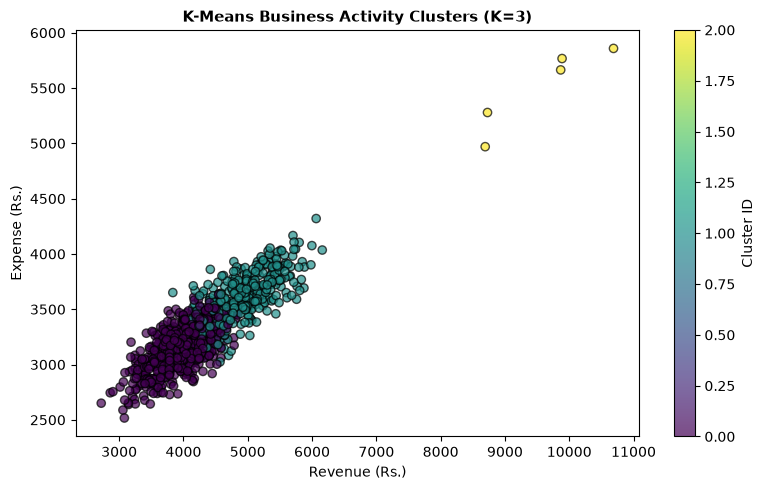

In [3]:
# Fit Final Model with K=3
chosen_k = 3
clus_pipe = Pipeline([('scaler', StandardScaler()), ('kmeans', KMeans(n_clusters=chosen_k, random_state=42, n_init=10))])
df_clean['cluster'] = clus_pipe.fit_predict(X)

# 2D Scatter Plot
plt.figure(figsize=(8, 5))
scatter = plt.scatter(df_clean['revenue'], df_clean['total_expense'], c=df_clean['cluster'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.title("K-Means Business Activity Clusters (K=3)", fontsize=11, fontweight='bold')
plt.xlabel("Revenue (Rs.)")
plt.ylabel("Expense (Rs.)")
plt.colorbar(scatter, label='Cluster ID')
plt.tight_layout()
plt.show()


In [4]:
# Joblib Save & Test
cluster_names = {0: "Low Activity", 1: "Moderate Steady", 2: "High Surge Activity"}
joblib.dump({"pipeline": clus_pipe, "feature_cols": feature_cols, "cluster_names": cluster_names, "k": chosen_k}, "../models/clustering_model.joblib")
del clus_pipe
loaded_data = joblib.load("../models/clustering_model.joblib")

sample = np.array([[4500.0, 11500.0, 75, 88.0]])
c_id = int(loaded_data["pipeline"].predict(sample)[0])
print(f"Cluster Assigned: {c_id} ({loaded_data['cluster_names'].get(c_id)})")


Cluster Assigned: 2 (High Surge Activity)
